# Adapter 전문가를 없앤 단일 모델 · 최종 평가

IF / MiniBatch K-means / LOF 각각 탐지기 **하나**. 각 입력은 **현재·과거 피처 17개 + Adapter 통계 피처 9개 = 26개**. 알고리즘 간 앙상블도 없다.

## 1. 핵심 결과

- IF: F1 38.56% → 55.01%, 정상 오탐률 13.31% → 3.15%
- K-means: F1 42.56% → 50.09%, 정상 오탐률 12.04% → 2.42%
- LOF: F1 42.66% → 53.04%, 정상 오탐률 6.45% → 2.48%

아래 결과는 컬럼 관계·Hard를 포함한 기존 전체 2,167,766분 판정이다. 1행의 Process 원본 판정과는 구분한다.

,accuracy,precision,recall,f1,normal_false_positive_rate
method,,,,,
if,87.46,74.70,43.53,55.01,3.15
kmeans,86.94,76.64,37.20,50.09,2.42
lof,87.44,77.66,40.27,53.04,2.48


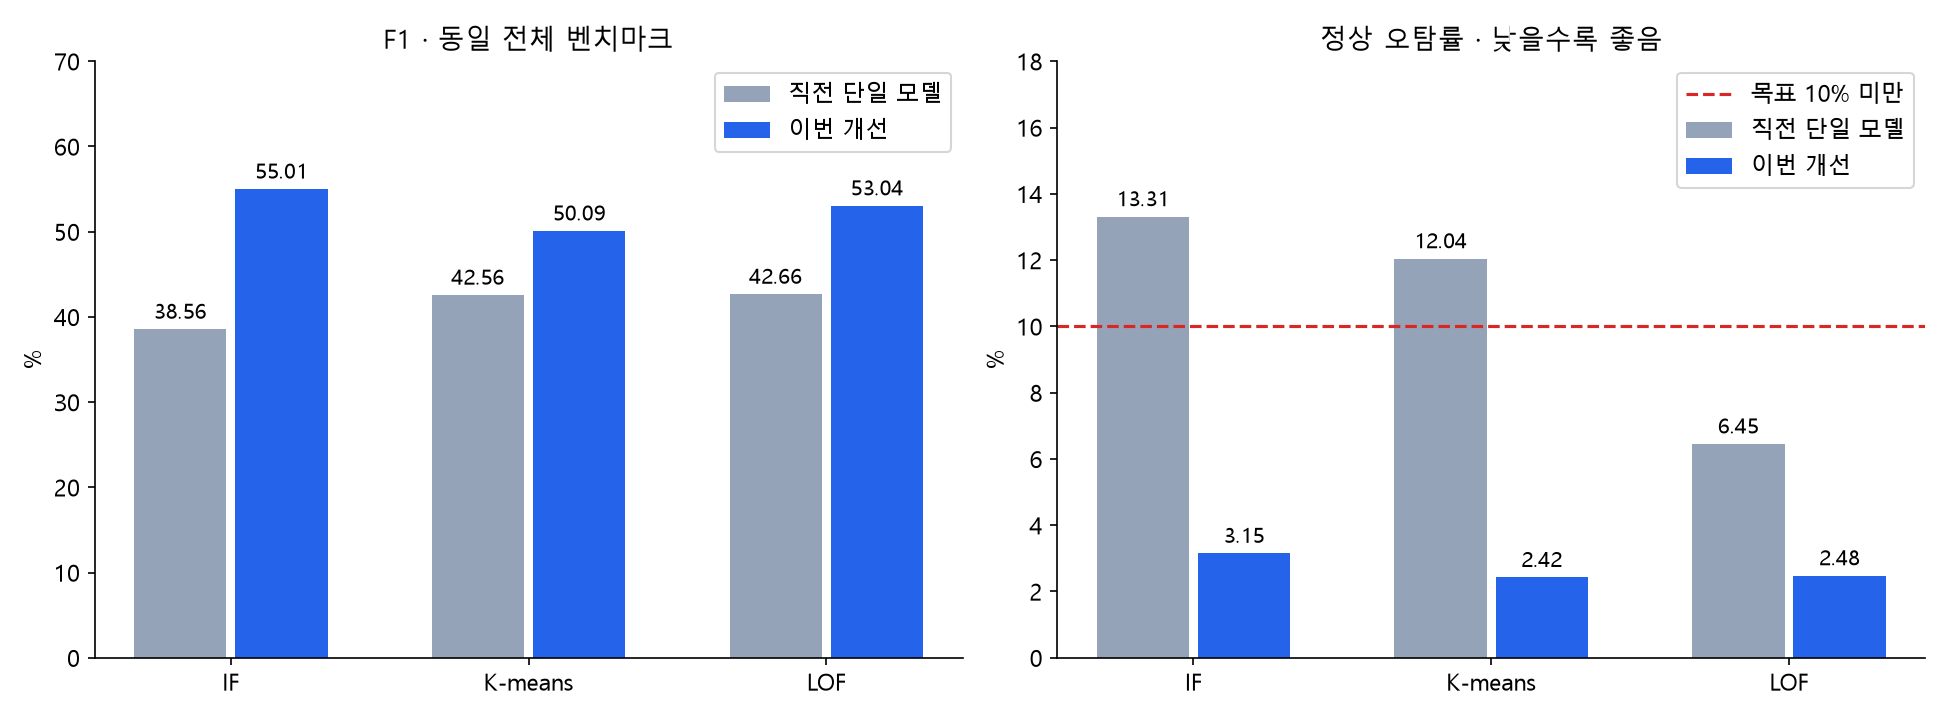

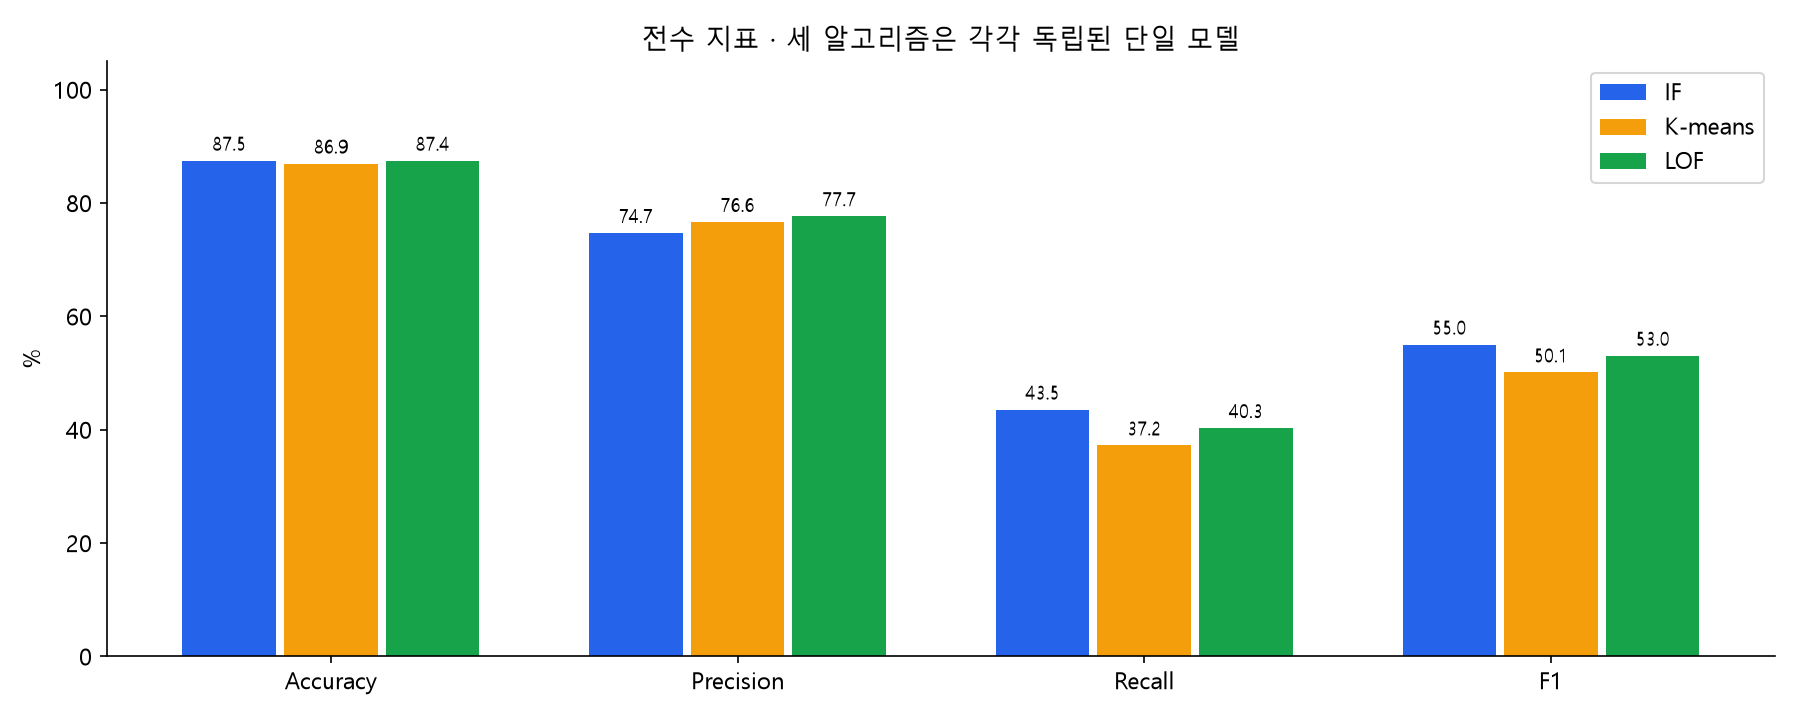

In [1]:
from pathlib import Path
import json, pandas as pd
from IPython.display import display, Image, Markdown
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'reports/shared_model_target_lof/summary.json').exists())
OUT=ROOT/'reports/shared_model_target_lof'
read=lambda p: json.loads(p.read_text(encoding='utf-8'))
result=read(OUT/'summary.json'); selected=read(OUT/'selection.json')
def metrics(rows):
    cols=['accuracy','precision','recall','f1','normal_false_positive_rate']
    return (pd.DataFrame(rows).set_index('method')[cols]*100).round(2)
display(metrics(result['pooled']))
display(Image(filename=str(OUT/'figures/comparison.png')))
display(Image(filename=str(OUT/'figures/metrics.png')))

**해석:** F1은 Precision과 Recall의 균형이다. 오탐률은 `FP / (TN + FP)`이며 정상 구간을 경보한 비율이다. 항상 정상이라고 해도 Accuracy는 82.39%이므로 정확도 하나만 보지 않는다. 세 알고리즘이 모든 시나리오에서 동시에 개선됐다는 뜻도 아니다.

## 2. 무엇을 왜 바꿨나

- 과거 5~15분 지연이 복구 후에도 남아 정상 구간을 오탐하는 문제 확인. 현재 완료 **1분** 소요시간을 중심으로 피처 재구성.
- 최근 추세는 과거만 비교하되 현재 지연이 없어지면 추세·누적 지연의 영향도 줄어드는 연속 피처 상호작용 추가. 하드 룰 추가가 아님.
- Adapter P95 참고 기준도 과거 5분 P95에서 현재 1분 완료 P95로 교체. `totalCount` 구간은 과거 5분 평균을 사용.
- IF: 정상 공분산 축소 추정 + 공통 고정 회전. K-means: 군집 수와 정상 군집 반경. LOF: 중복 제거·이웃 수·참고 표본 수 비교.
- 완료 로그가 없는 분과 있는 분의 점수 분포를 정상 참고 통계로 보정. Adapter 전문가 모델을 만든 것이 아님.

## 3. 학습·설정 선택·평가를 구분

정상 S 후보로 만든 train **19,793분**에서 모델·스케일러·Adapter 통계 학습. 정상 calibration **17,925분**에서 점수 참고 분포와 경보선 후보 생성. 기존 두 개발 분할 **35,782분 / 71,618분**에서 모두 오탐률 8% 미만인 후보 중 합산 F1로 설정 선택. 이 단계는 정답 라벨을 활용했다.

기존 결과를 보며 구조를 개선했으므로 기존 벤치마크는 외부 블라인드 테스트가 아니다. 원본 전 기간의 모든 행을 직접 학습한 것도 아니다. S는 성능 정상 보장이 아닌 정상 후보이다.

In [2]:
rows=[]
for a,r in selected['selected'].items():
    for name,v in r['folds'].items(): rows.append({'method':a+' / 개발 '+name,**v})
display(metrics(rows))
fresh=read(OUT/'fresh_confirmation_v2.json')
display(Markdown('### 설정 동결 후 새 seed로 만든 확인 사례 · 재선택에 사용하지 않음'))
display(metrics(fresh['pooled']))
display(Markdown('원본 생성기에서 시나리오당 이상 120사례+정상 대조 120사례. 같은 원본 pool을 공유하며 외부 운영 검증은 아님. seed='+str(fresh['seed'])))

,accuracy,precision,recall,f1,normal_false_positive_rate
method,,,,,
if / 개발 search,88.39,73.87,44.44,55.49,3.06
if / 개발 confirmation,86.83,60.72,51.35,55.64,6.37
kmeans / 개발 search,87.67,77.78,33.95,47.27,1.89
kmeans / 개발 confirmation,86.55,60.65,46.61,52.71,5.80
lof / 개발 search,88.46,78.99,39.63,52.78,2.05
lof / 개발 confirmation,87.79,66.90,47.72,55.70,4.53


### 설정 동결 후 새 seed로 만든 확인 사례 · 재선택에 사용하지 않음

,accuracy,precision,recall,f1,normal_false_positive_rate
method,,,,,
if,87.61,65.70,48.22,55.62,4.83
kmeans,87.15,66.37,40.89,50.60,3.98
lof,88.05,70.89,43.75,54.11,3.45


원본 생성기에서 시나리오당 이상 120사례+정상 대조 120사례. 같은 원본 pool을 공유하며 외부 운영 검증은 아님. seed=41200042

## 4. 시나리오별 성능과 모델 차이

각 모델은 시나리오 이름을 맞히는 것이 아니라 이상 점수만 출력한다. 같은 피처를 넣어도 점수 계산 방식 때문에 결과가 다르다. **이번 합성 평가에서 관측된 차이**이지 알고리즘이 특정 장애에 항상 강하다는 보장은 아니다. 집단 지연은 같은 Adapter+Process 스트림의 반복 실행 지연이며 Adapter 전체의 여러 Process 동시 지연 실증은 아니다.

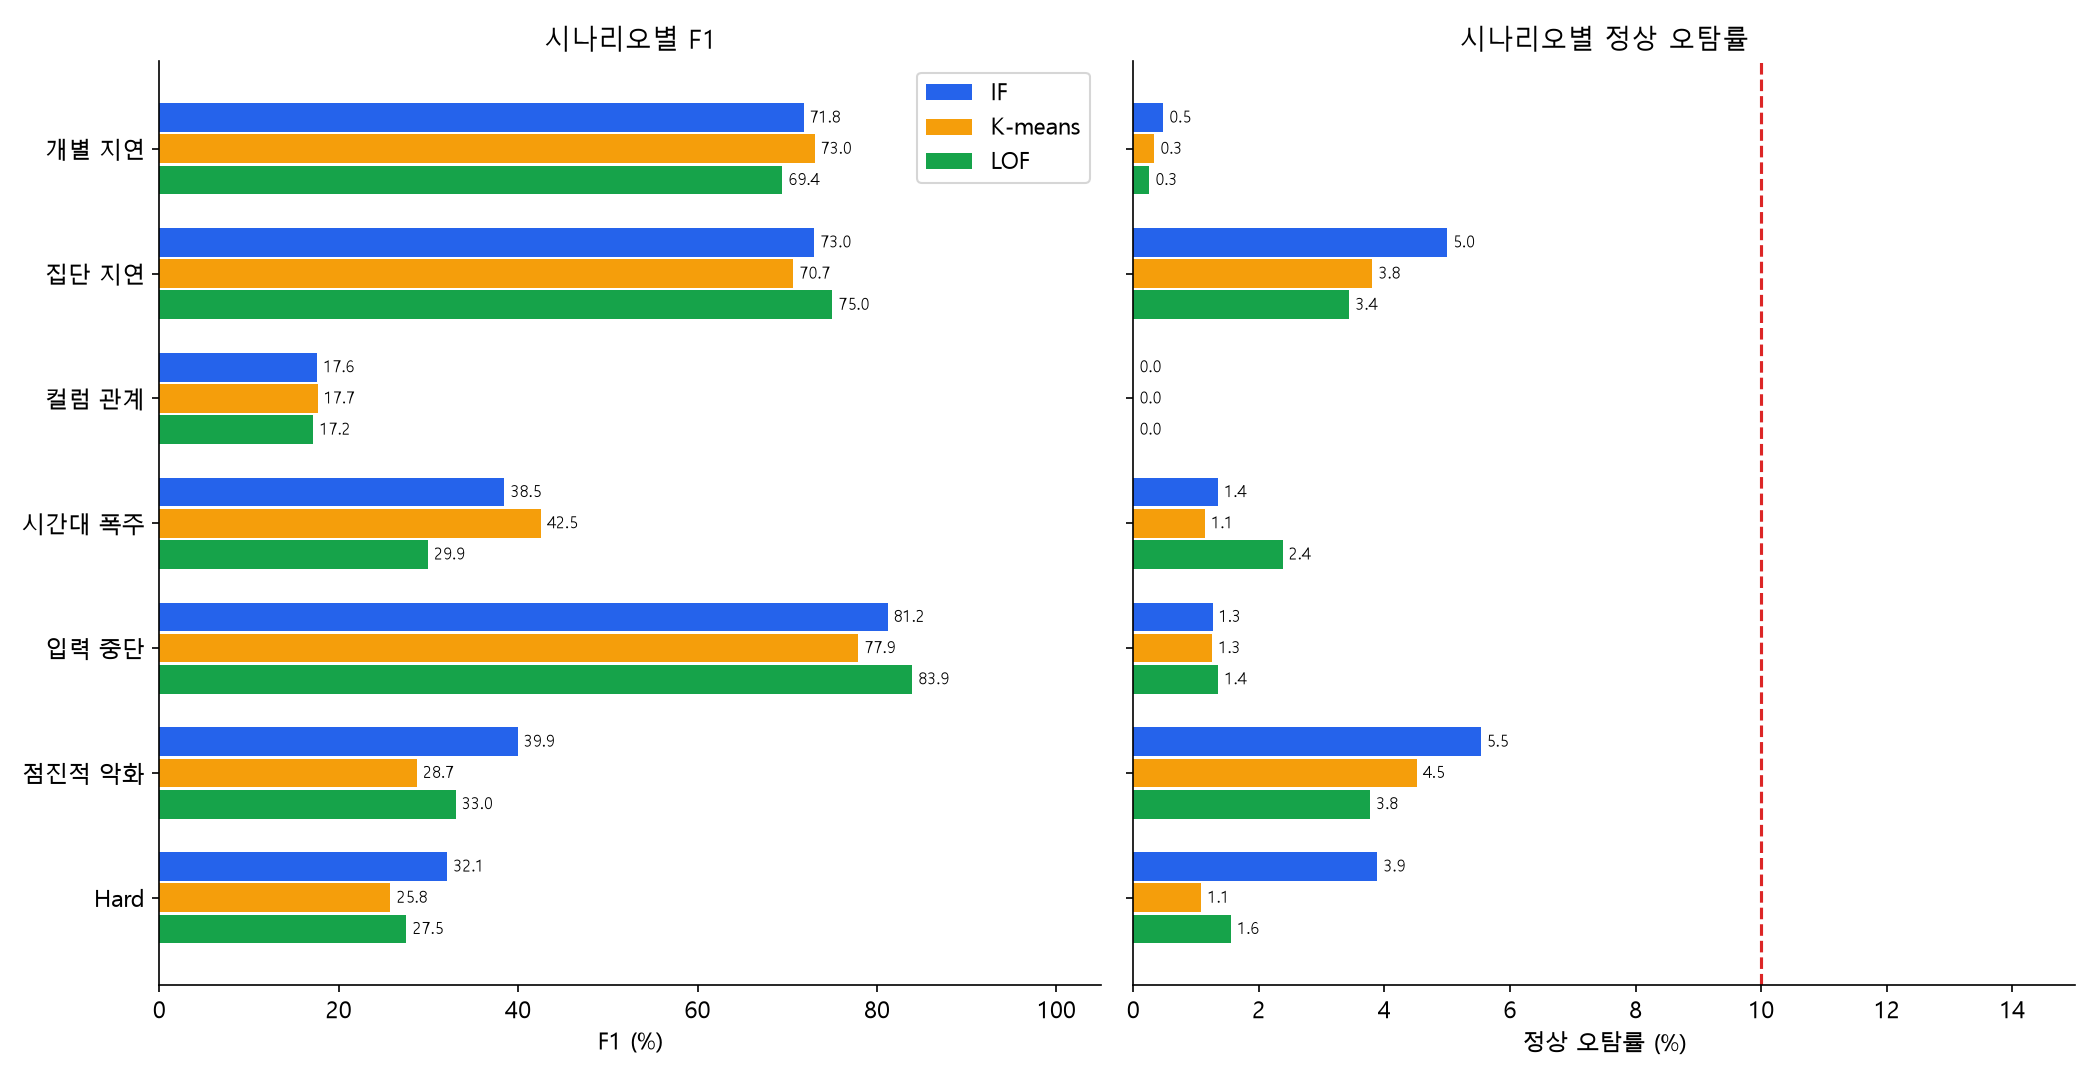

### individual_delay

,accuracy,precision,recall,f1,normal_false_positive_rate
method,,,,,
if,96.08,92.02,58.88,71.82,0.47
kmeans,96.27,94.34,59.59,73.04,0.33
lof,95.92,95.24,54.64,69.44,0.25


### group_delay

,accuracy,precision,recall,f1,normal_false_positive_rate
method,,,,,
if,91.76,72.45,73.55,73.00,4.99
kmeans,91.66,75.66,66.29,70.67,3.81
lof,92.78,78.79,71.59,75.02,3.44


### column_relation

...

,accuracy,precision,recall,f1,normal_false_positive_rate
method,,,,,
if,94.62,91.61,72.88,81.18,1.26
kmeans,93.86,91.10,68.09,77.93,1.26
lof,95.27,91.54,77.47,83.92,1.36


### gradual_degradation

,accuracy,precision,recall,f1,normal_false_positive_rate
method,,,,,
if,78.21,63.56,29.12,39.94,5.53
kmeans,76.47,58.29,19.04,28.71,4.51
lof,77.77,65.94,22.04,33.03,3.77


### mixed_hard

,accuracy,precision,recall,f1,normal_false_positive_rate
method,,,,,
if,79.56,61.51,21.70,32.09,3.89
kmeans,80.32,80.19,15.35,25.77,1.09
lof,80.29,75.56,16.84,27.55,1.56


In [3]:
display(Image(filename=str(OUT/'figures/scenarios.png')))
for dataset in result['datasets']:
    display(Markdown('### '+dataset['dataset']))
    display(metrics(dataset['metrics']))

## 5. 입력 데이터 분포

왼쪽: 같은 Adapter·처리건수 구간의 정상 소요시간 대비 편차. 오른쪽: 과거 실행 주기에 비해 로그가 오랫동안 비어 있는 정도. 원래 요청이 적은 스트림에서 단순히 로그 0건이라고 이상으로 정하지 않기 위한 문맥이다. **표본 그림**이며 전수 지표는 위 표를 사용한다.

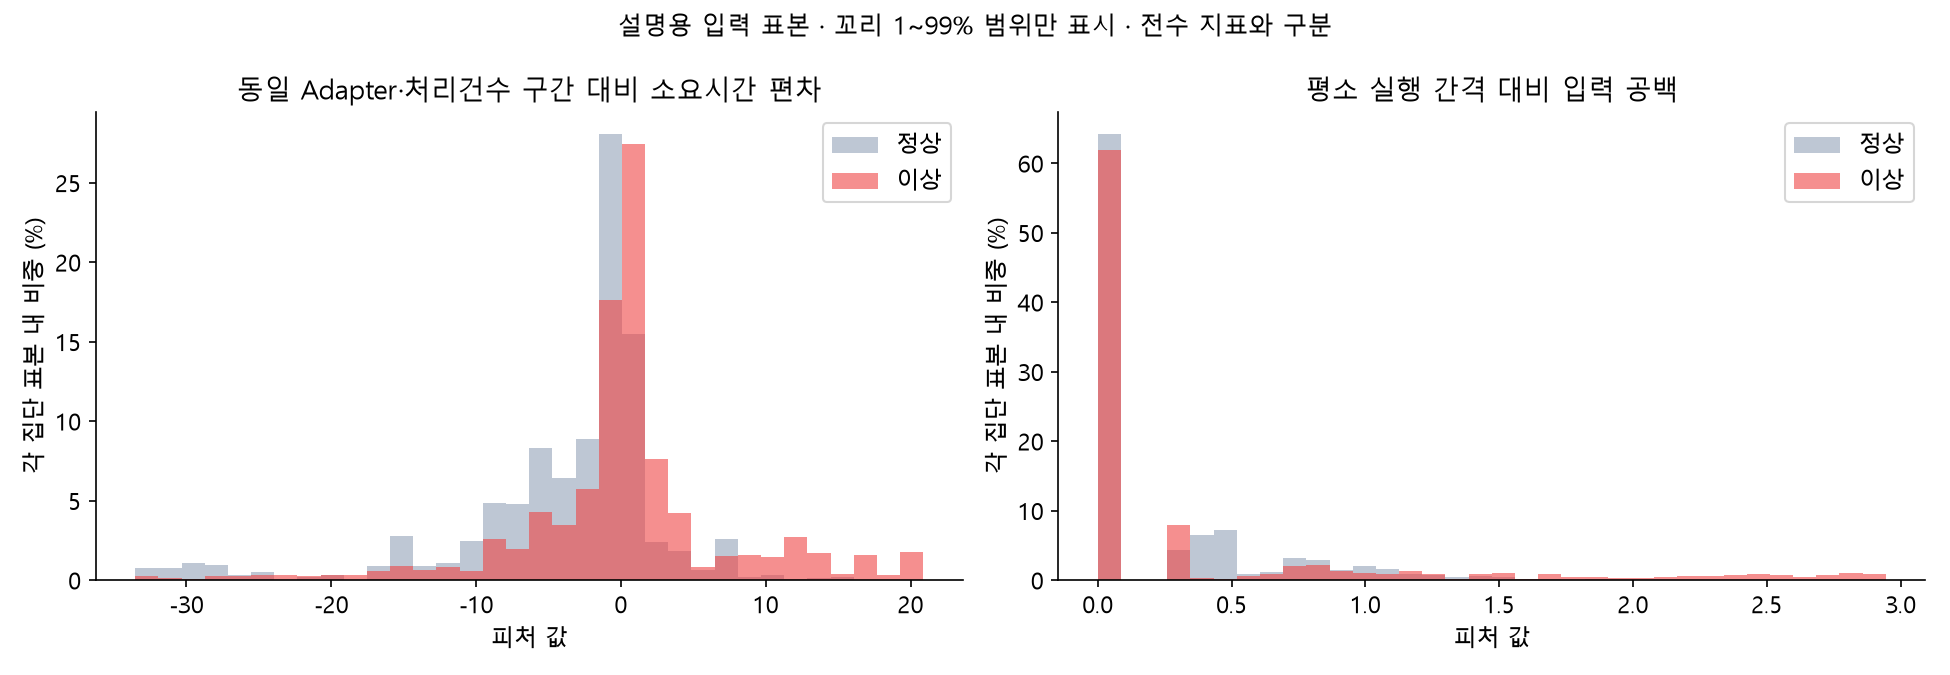

,실제 피처명,의미
0,current_arrival_excess,현재 1분 실행 횟수의 기존 기준 대비 양수 편차
1,current_prefix_burst,현재 실행 횟수 / 먼저 관측한 최대 8분 평균 실행 횟수의 양수 log 비율
2,gap_expected_prefix,초기 관측 실행 주기로 보정한 연속 입력 공백
3,gap_expected_recent,최근 과거 실행 주기로 보정한 연속 입력 공백
4,empty_expected_rate,평소 실행이 예상되지만 현재 실행이 없는 정도
5,current_source_delay,현재 완료 로그의 조건부 소요시간 잔차 중 양수 부분을 asinh 압축
6,current_source_upper,현재 완료 소요시간이 정상 참고 분포의 위쪽 꼬리에서 드문 정도
7,current_source_lower,현재 완료 소요시간이 정상 참고 분포의 아래쪽 꼬리에서 드문 정도
8,current_prefix_delay,현재 잔차와 먼저 관측한 최대 8개 완료 분의 중앙값 차이 / MAD 하한
9,current_recent_delay,현재 잔차와 직전 최대 15분의 잔차 중앙값 차이 / MAD 하한


In [4]:
display(Image(filename=str(OUT/'figures/inputs.png')))
desc=read(OUT/'feature_descriptions.json')
display(pd.DataFrame(desc.items(),columns=['실제 피처명','의미']))

## 6. 전수 점수 분포와 실제 threshold

일반 막대 히스토그램이다. 정상과 이상 집단 각각 전체를 분모로 삼는다. **점선보다 큰 점수**가 경보이다. 표시 범위를 벗어난 꼬리 비중은 제목에 표시하며, 성능 계산에서는 한 건도 제외하지 않았다. IF·K-means는 정상 경험적 꼬리 보정, LOF는 정상 중앙값/P95 폭 보정이라 점수 크기를 서로 직접 비교하면 안 된다. 점수는 확률이 아니고 q=.99가 운영 오탐률 1%를 보장하지 않는다.

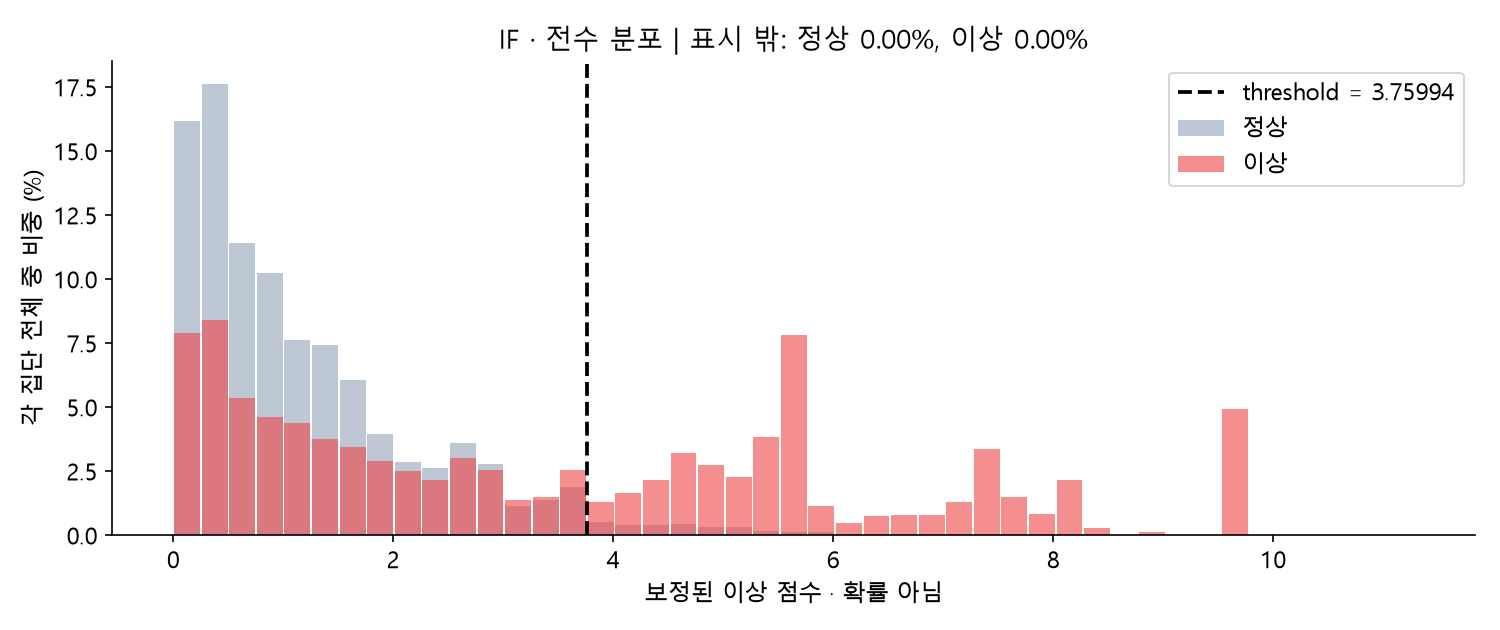

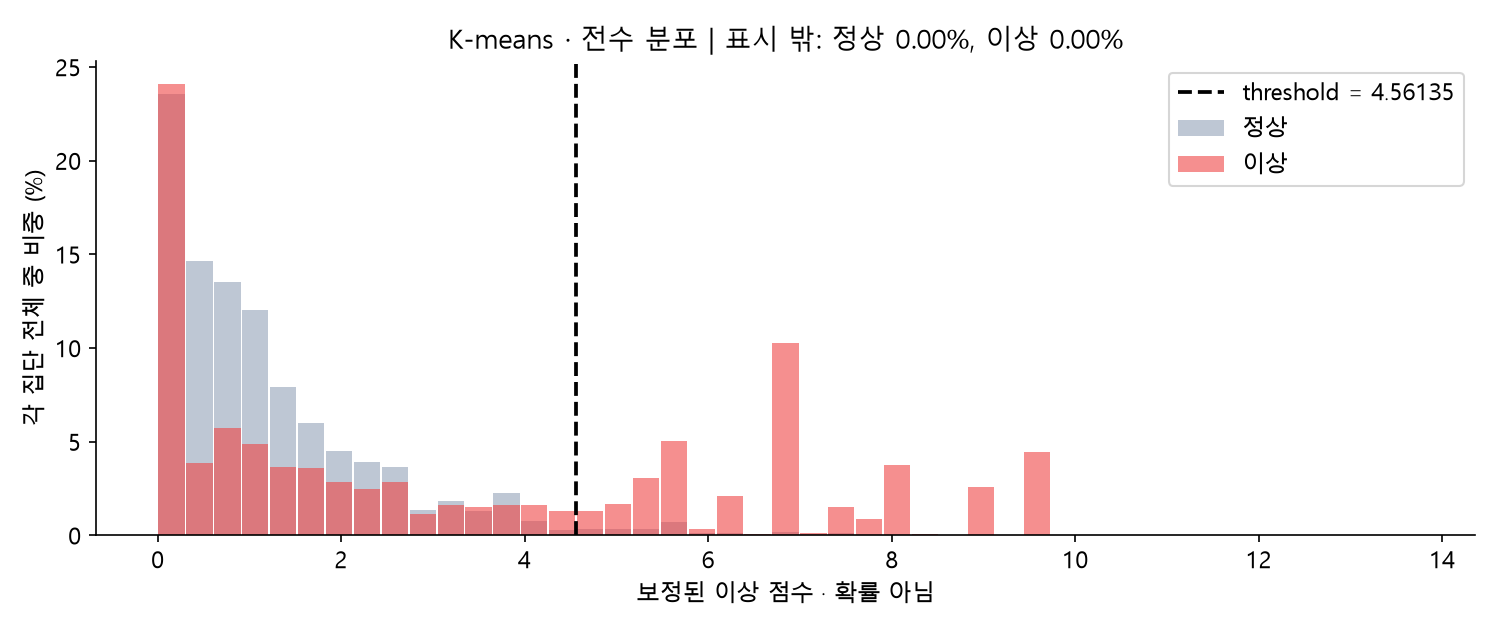

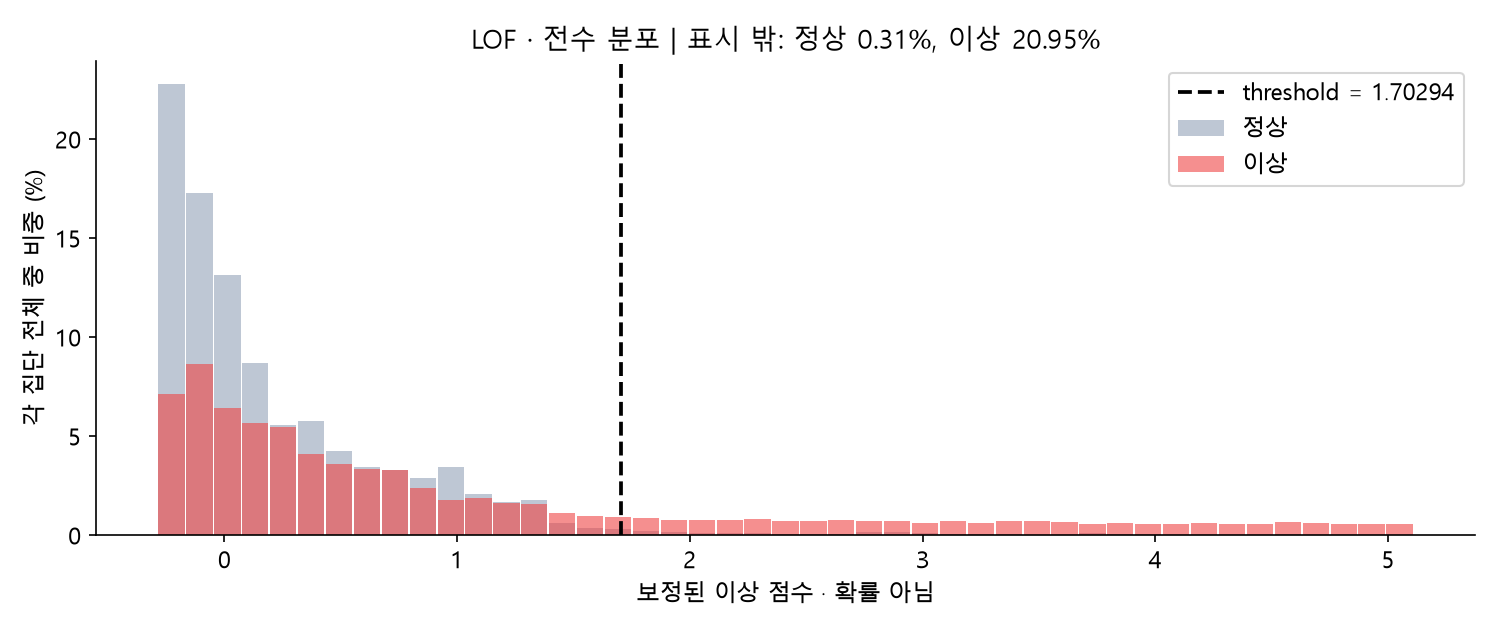

In [5]:
for a in ['if','kmeans','lof']:
    display(Image(filename=str(OUT/'figures'/f'{a}_threshold.png')))

## 7. 정확한 하이퍼파라미터

공통 seed=42, hybrid 압축·안정화, Adapter 피처 양수 가중치 .25. 아래 표에서 해당 알고리즘에 사용한 값만 읽는다. 모델 하나에 군집/이웃/트리를 모두 쓰는 것이 아니다.

In [6]:
manifest=read(OUT/'handoff/manifest.json')
for r in manifest['models']:
    a=r['algorithm']; s=r['settings']
    keys={'if':['trees','samples','whitening','rotation'],'kmeans':['clusters','geometry'],'lof':['neighbors','reference_cap','metric']}[a]
    values={k:s[k] for k in ['transform','adapter_weight',*keys]}
    values.update({'입력 피처 수':len(r['columns']),'Adapter 피처 수':r['adapter_feature_count'],'학습/참고 행 수':r['fit_rows'],'정상 점수 quantile':selected['selected'][a]['q'],'score threshold':r['threshold'],'점수 보정':r['calibration_mode']+' / '+r['calibration_kind'],'탐지기 수':r['estimator_count']})
    display(Markdown('### '+a)); display(pd.Series(values,name='설정').to_frame())
display(Markdown('K-means 고정값: batch_size=2048, n_init=10, max_iter=150. 중심까지의 거리를 군집별 정상 P95 반경으로 나눈 뒤 최솟값 사용. LOF는 novelty=True, 정상 중복 제거 후 최대 4096개 참조.'))

### if

,설정
transform,hybrid
adapter_weight,0.25
trees,300
samples,256
whitening,True
rotation,True
입력 피처 수,26
Adapter 피처 수,9
학습/참고 행 수,19793
정상 점수 quantile,0.98


### kmeans

,설정
transform,hybrid
adapter_weight,0.25
clusters,16
geometry,radius
입력 피처 수,26
Adapter 피처 수,9
학습/참고 행 수,19793
정상 점수 quantile,0.99
score threshold,4.561352
점수 보정,availability / cdf


### lof

,설정
transform,hybrid
adapter_weight,0.25
neighbors,500
reference_cap,4096
metric,euclidean
입력 피처 수,26
Adapter 피처 수,9
학습/참고 행 수,4096
정상 점수 quantile,0.99
score threshold,1.702942


K-means 고정값: batch_size=2048, n_init=10, max_iter=150. 중심까지의 거리를 군집별 정상 P95 반경으로 나눈 뒤 최솟값 사용. LOF는 novelty=True, 정상 중복 제거 후 최대 4096개 참조.

## 8. 실시간 연결 시 의미

완료된 Process 로그와 현재까지의 과거 상태로 연속 1분 grid를 만든다. `Adapter+Process ID`별 상태를 유지하며 로그가 없는 분도 생성해야 입력 중단을 탐지할 수 있다. 현재 완료된 소요시간만 사용하므로 미래 t+k 완료 로그는 읽지 않는다.

초기 기준은 먼저 **관측한** 최대 8분/8개 완료 분이지 정상이라고 보장된 초반이 아니다. 새 Adapter는 전체 참고 통계로 대체한다. 모델 저장/재로딩·미등록 Adapter 추론은 감사 스크립트로 점검하지만 운영 워커의 상태 보관·지연 로그 처리·배포는 별도 작업이다.

## 9. ADBench 활용 판단

[ADBench 공식 저장소](https://github.com/Minqi824/ADBench), [NeurIPS 2022 논문](https://arxiv.org/abs/2206.09426).

- **추천:** 현재 Process 피처 표의 알고리즘 비교, global/local/cluster/dependency 유형별 스트레스 테스트, 무관 피처·라벨 오염·중복 이상에 대한 강건성 비교.
- **주의:** 기본 생성기는 GMM/분포 변형 기반의 표형 데이터 생성이다. 시간 순서·입력 중단·점진적 악화·SQL/하드 룰 정합성을 자동으로 보장하지 않는다. 원시 로그에 그대로 넣는 도구는 아님.
- 따라서 현재 **시간 순서 기반 로그 시나리오는 유지**, ADBench는 별도 보조 평가 축으로 사용하는 편이 적합하다. 분할은 random split을 그대로 쓰지 말고 시간/사례/원본 템플릿 기준으로 누수를 통제해야 한다.
- 이번 결과에 ADBench를 설치·실행하거나 기존 벤치마크를 교체하지는 않았다. 제안 단계이다.

## 10. 참고 근거와 한계

- [EIF 논문](https://arxiv.org/abs/1811.02141)의 축 정렬 편향 문제를 참고. **이번 IF는 고정 공통 회전 1개 + 기존 IF**이며 EIF 전체 구현이 아니다.
- [OAS 공식 문서](https://scikit-learn.org/stable/modules/generated/sklearn.covariance.OAS.html): 정상 공분산 축소 추정으로 전처리 안정화. 추가 탐지 모델 아님.
- [LOF 공식 문서](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.LocalOutlierFactor.html): novelty 모드와 이웃 크기/거리 설정. 이웃 500은 더 넓은 주변을 비교하므로 미세한 국소 이상 민감도와 비용의 절충이 있다.
- 기존 데이터·정답·기존 모델을 유지. 정상/이상 전체 분 판정, point adjustment 없음. 최종 평가 결과를 보고 threshold를 골라 끼우지 않음.
- 낮은 오탐률은 이번 합성 평가 관측값이다. 합성 시간대 prior와 공유 원본 pool 때문에 실제 운영 일반화·정식 오탐률 보장은 불가.
- 이전 confirmation의 위치 기반 라벨 연결 오류는 별도 새 확인 입력에서 case_id+window_start 키 정렬로 수정. 기존 전수 벤치마크는 원래부터 키 기반 정렬이며 이 오류의 영향을 받지 않음.
- GitHub·Notion·운영 배포 변경 없음.